## 3.1 Linear Basis Function Models

The simplest linear regression model

$$
\begin{align}
y(x,\textbf{w}) &= w_0 + w_1 x_1 + \cdots + w_D x_D \newline
x &= \begin{bmatrix} x_1 & x_2 & x_3 & \ldots & x_{D}  \end{bmatrix}^T \newline
\end{align}
$$

This is very simple model. This can be extended with basis functions.

Rewriting above equation using basis function and total number of parameters $M$ (Do not get confused with $D$ in above equation)

$$
\begin{align}
y(x,\textbf{w}) &= w_0 + \sum_{j=1}^{M-1} w_j \phi_{j}(x) \newline
y(x,\textbf{w}) &= \sum_{j=0}^{M-1} w_j \phi_{j}(x) = \textbf{w}^T \phi (x) \quad ,where \quad \phi_{0} = 1 \newline
\textbf{w} &= \begin{bmatrix} w_0 & w_1 & w_2 & \ldots & w_{M-1}  \end{bmatrix}^T \newline
\phi(x) &= \begin{bmatrix} \phi_0(x) & \phi_1(x) & \phi_2(x) & \ldots & \phi_{M-1}(x)  \end{bmatrix}^T \quad ,where \quad \phi_{0}(x) = 1 
\end{align}
$$

Note : $\phi$ is function of $x$

Basis function can be non-linear. However regression represented here is called linear model because it is linear in $\textbf{w}$

Gaussian basis function (It is not required to be normalized)

$$
\begin{align}
\phi_{j}(x) &= exp\left[ - \frac{\left( x - \mu_{j}\right)^2}{ 2 s^2}\right]
\end{align}
$$

Sigmoidal basis function

$$
\begin{align}
\phi_{j}(x) &= \sigma \left( \frac{x - \mu_{j}}{s}\right) \newline
where, \quad \sigma(a) &= \frac{1}{1 + exp(-a)}
\end{align}
$$

It could be $tanh(a) = 2 \sigma(2a) - 1$

It could be Fourier basis.

### 3.1.1 Maximum likelihood and least square

$$
\begin{align}
t &= y(x, w) + \epsilon \newline
&\epsilon \sim \mathcal{N}(0, \beta^{-1}) \newline
p(t|x, w, \beta) &= \mathcal{N}(t|y(x,w), \beta^{-1}) \newline
\end{align}
$$


Assuem a squared loss function (Section 1.5.5), the optimal prediction, for new value of $x$ is conditional mean of the target variable.
The conditional mean is,
$$
\begin{align}
E[t|x] &= \int t p(t|x) dt = y(x,w)
\end{align}
$$

$\epsilon$ is called **precision** (inverse variance)

Note that gaussian noise assumption implies that the conditional distribution is *unimodel* (roughly, one peak in the distribution) which might not be applicable for all scenarios. In some cases, it is appropriate to model as mixture of conditional gaussian distributions (Section 14.5.1)

Think : Why does term $w, \beta$ disappeared from the probability distribution when conditional mean is calculated? - The conditional mean is for new value of $x$. This implies that you know parameter $w, \beta$ and for a new (or next) value $x$, the best prediction under square loss minimization is given by $y(x,w)$.

#### Estimation of $w$ with N inputs

This section describes how to estimate the model weights and prior precision given input and target using MLE with least squares.

Assume that input vector $\mathbf{X}$ is i.i.d. sampled.


$$
\begin{align}
\mathbf{X} &= \begin{bmatrix} x_1 & x_2 & x_3 & \ldots & x_{N}  \end{bmatrix}^T \newline
\mathbf{t} &= \begin{bmatrix} t_1 & t_2 & t_3 & \ldots & t_{N}  \end{bmatrix}^T \newline
\textbf{w} &= \begin{bmatrix} w_0 & w_1 & w_2 & \ldots & w_{M-1}  \end{bmatrix}^T \newline
\phi(x_n) &= \begin{bmatrix} \phi_0(x_n) & \phi_1(x_n) & \phi_2(x_n) & \ldots & \phi_{M-1}(x_n)  \end{bmatrix}^T \quad ,where \quad \phi_{0}(x_n) = 1 
\end{align}
$$

Since basis function depend on input $x$, they are different for each input i.e. $x_n$. However, weights $w$ are same for all inputs.

Read secion 1.2.5 to know more about following formula

$$
p(\mathbf{t}|\mathbf{X},\mathbf{w},\beta) = 
\prod_{n=1}^N \mathcal{N}(t_n|y(\mathbf{x}_n,\mathbf{w}),\beta^{-1}) = 
\prod_{n=1}^N \mathcal{N}(t_n|\mathbf{w}^{\text{T}}\mathbf{\phi}(\mathbf{x}_n),\beta^{-1})
$$

Dropping $\mathbf{X}$ from $p(\mathbf{t}|\mathbf{X},\mathbf{w},\beta)$

$$
\begin{align}
\ln p(\mathbf{t}|\mathbf{w},\beta) &= 
\sum_{n=1}^N \ln\mathcal{N}(t_n|\mathbf{w}^{\text{T}}\mathbf{\phi}(\mathbf{x}_n),\beta^{-1}) \\
&= \frac{N}{2}\ln\beta - \frac{N}{2}\ln 2\pi - 
\frac{\beta}{2}\sum_{n=1}^N \big(t_n - \mathbf{w}^{\text{T}}\mathbf{\phi}(\mathbf{x}_n)\big)^2 \\
&= \frac{N}{2}\ln\beta - \frac{N}{2}\ln 2\pi - \beta E_D(\mathbf{w}) \\
where, E_D &= \frac{1}{2}\sum_{n=1}^N \big(t_n - \mathbf{w}^{\text{T}}\mathbf{\phi}(\mathbf{x}_n)\big)^2 = \frac{1}{2}\sum_{n=1}^N \big(t_n - y(\mathbf{x}_n, \mathbf{w}))\\
\nabla_{w} \ln p(\mathsf{t}|\mathbf{w},\beta) &= 
\beta \sum_{n=1}^N \big(t_n - \mathbf{w}^{\text{T}}\mathbf{\phi}(\mathbf{x}_n)\big)\mathbf{\phi}(\mathbf{x}_n)^{\text{T}} \\
\end{align}
$$

> [!Note]
>Maximing log likelihood with respect to $w$ under conditional gaussian noise for linear model is equivalent to minimizing sum-of-square errors of $E_D$

Following equation is called *normal equations* for least square problem.

$$
\boxed{
\mathbf{w}_{ML} = (\mathbf{\Phi}^{\text{T}}\mathbf{\Phi})^{-1}\mathbf{\Phi}^{\text{T}}\mathsf{t}
}
$$

$$
\mathbf{w}_{ML} = \mathbf{\Phi}^\dagger \mathsf{t} \newline
\mathbf{\Phi}^\dagger \equiv \mathbf{\Phi}^{-1}
$$

$$
\mathbf{\Phi}= 
\begin{pmatrix}
\phi_0(\mathbf{x}_1) & \phi_1(\mathbf{x}_1) & \cdots & \phi_{M-1}(\mathbf{x}_1) \\
\phi_0(\mathbf{x}_2) & \phi_1(\mathbf{x}_2) & \cdots & \phi_{M-1}(\mathbf{x}_2) \\
\vdots  & \vdots  & \ddots & \vdots  \\
\phi_0(\mathbf{x}_N) & \phi_1(\mathbf{x}_N) & \cdots & \phi_{M-1}(\mathbf{x}_N)
\end{pmatrix}
$$

**Notes**
- $\Phi$ is NxM matrix, called *design matrix*.
- $\mathbf{\Phi}^\dagger$ called *Moore-Penrose pseudo-inverse* of matrix $\Phi$ and $\mathbf{\Phi}^\dagger = (\mathbf{\Phi}^{\text{T}}\mathbf{\Phi})^{-1}\mathbf{\Phi}$
- Elements of $\Phi$ is given by $\Phi_{nj} = \phi_j(x_n)$ where $n$ is row and $j$ is column

#### Estimation of $w_0$

Rewriting $E_D$ such that $w_0$ is explicit

$$
E_D(w) = \frac{1}{2} \sum_{n=1}^{N} \left( t_n - w_0 - \sum_{j=1}^{M-1} w_j \phi_{j}(x_n) \right)
$$

Derivative with respect to $w_0$

$$
\begin{aligned}
\frac{\partial E_D}{\partial w_0} &=
\frac{1}{2}\sum_{n=1}^{N}
2\left(
t_n-w_0-\sum_{j=1}^{M-1}w_j\phi_j(x_n)
\right)(-1) \newline
&=
-\sum_{n=1}^{N}
\left(
t_n-w_0-\sum_{j=1}^{M-1}w_j\phi_j(x_n)
\right)
\end{aligned}
$$

Setting derivative to zero

$$
\begin{aligned}
\sum_{n=1}^{N} \left(t_n - w_0 - \sum_{j=1}^{M-1}w_j\phi_j(x_n) \right) &= 0 \\
\sum_{n=1}^{N} t_n - \sum_{n=1}^{N} w_0 - \sum_{n=1}^{N} \sum_{j=1}^{M-1} w_j\phi_j(x_n) &= 0 \\
\sum_{n=1}^{N} t_n - N w_0 - \sum_{n=1}^{N} \sum_{j=1}^{M-1} w_j\phi_j(x_n) &= 0 \\
\end{aligned}
$$

$$
\begin{aligned}
N w_0 &= \sum_{n=1}^{N}t_n - \sum_{n=1}^{N} \sum_{j=1}^{M-1} w_j\phi_j(x_n) \\
w_0 &= \frac{1}{N}\sum_{n=1}^{N}t_n - \frac{1}{N} \sum_{n=1}^{N} \sum_{j=1}^{M-1} w_j\phi_j(x_n) \\
\end{aligned}
$$

$$
\boxed{ w_0 = \bar{t} - \sum_{j=1}^{M-1} w_j \bar{\phi_{j}} }
$$

$$
\begin{aligned}
\bar{t} &=\frac{1}{N}\sum_{n=1}^{N}t_n, \quad
\bar{\phi_{j}} &=\frac{1}{N}\sum_{n=1}^{M-1} \phi_j(x_n)
\end{aligned}
$$

>[!Note] bias $w_0$ compensates for the difference between the averages over training set (target) and the weighted sum of the averages of the basis functions.

$\bar{\phi_{j}}$ is average of all elements in $j^{th}$ column of $\Phi$

#### Finding $\beta$
Maximizing log likelihood function with respect to $\beta$

$$
\begin{aligned}
\ln p(\mathbf{t}|\mathbf{w},\beta) &= 
\frac{N}{2}\ln\beta - \frac{N}{2}\ln 2\pi - \beta E_D(\mathbf{w}) \quad \\
\nabla_{\beta} \ln p(\mathbf{t}|\mathbf{w},\beta) &=  \frac{N}{2 \beta} - E_D(w) = 0 \\
\frac{1}{\beta} &= \frac{2}{N} E_D(w)
\end{aligned}
$$

Using estimated parameter $w_{ML}$,

$$
\boxed{
\frac{1}{\beta_{ML}} = \frac{1}{N}\sum_{n=1}^N (t_n - \mathbf{w_{ML}}^{\text{T}}\mathbf{\phi}(\mathbf{x}_n))^2
}
$$

Inverse of the noise precision is given by the residual variance of the target value around the regression function.

**Extras**
>![Note] $\equiv$ is called triple bar https://en.wikipedia.org/wiki/Triple_bar


### 3.1.2 Geometry of least squares

target is N-dimensional vector space whose axis is $t_n$

$$ \mathbf{t} = \begin{bmatrix} t_1 & t_2 & t_3 & \ldots & t_{N}  \end{bmatrix}^T \in \mathbf{R}^N$$

$\varphi_{j}$ is $j^{th}$ column of $\Phi$ where $j=0,1,2,\ldots,M-1$

$$ \varphi_{j} = \begin{bmatrix} \phi_j(x_1) & \phi_j(x_2) & \phi_j(x_3) & \ldots & \phi_j(x_N)  \end{bmatrix}^T$$

$\phi(x_n)$ is $n^{th}$ row of $\Phi$ where $n=1,2,\ldots,N$

$$ \phi(x_n) = \begin{bmatrix} \phi_0(x_n) & \phi_1(x_n) & \phi_2(x_n) & \ldots & \phi_{M-1}(x_n)  \end{bmatrix} $$

**Key idea**
- $\varphi_{j}$ is a vector in N-dimensional space.
- regression equation $y = \mathbf{w}^T \Phi  = w_0 \phi_0 + \ldots + w_{M-1} \phi_{M-1}$. 
- $y$ is linear combination of **M column vectors** and the span is $[\phi_0, \phi_1, \ldots, \phi_{M-1}]$

#### M < N
Suppose M=2 and N=3

This means that
 
$$
\Phi =
\begin{bmatrix}
\color{red}{\phi_0(x_1)} & \color{blue}{\phi_1(x_1)} \\
\color{red}{\phi_0(x_2)} & \color{blue}{\phi_1(x_2)} \\
\color{red}{\phi_0(x_3)} & \color{blue}{\phi_1(x_3)}
\end{bmatrix}
=
\begin{bmatrix}
\color{red}{\boldsymbol{\varphi}_0} &
\color{blue}{\boldsymbol{\varphi}_1}
\end{bmatrix}
$$

$$
\begin{aligned}
\mathbf{y} =
\begin{bmatrix}
y_1 \\ y_2 \\ y_3
\end{bmatrix}
&= \begin{bmatrix}
w_0\phi_0(x_1)+w_1\phi_1(x_1)\\
w_0\phi_0(x_2)+w_1\phi_1(x_2)\\
w_0\phi_0(x_3)+w_1\phi_1(x_3)
\end{bmatrix} \\

&= {\begin{bmatrix} \phi_0(x_1) \\ \phi_0(x_2)\\ \phi_0(x_3) \end{bmatrix}} w_0 
+
{\begin{bmatrix} \phi_1(x_1)\\ \phi_1(x_2)\\ \phi_1(x_3) \end{bmatrix}} w_1 \\

&= \varphi_0 w_0 + \varphi_1 w_1 \\

&= \begin{bmatrix} \varphi_0 & \varphi_1 \end{bmatrix} \begin{bmatrix} w_0 \\ w_1 \end{bmatrix} \\

&= \Phi \mathbf{w} \\

\end{aligned}
$$

> Extra: $y=\mathbf{w}^T \phi(x)$ is different from $\mathbf{y} = \Phi \mathbf{w}$.
> The first equation is for one output (target) and the second equation is for N stacked output (targets)

Check equation of $y$. 
- If these two vectors $\phi_0$ and $\phi_1$ are independent, then they **span** a two dimension **subspace** (plane) inside three dimensional space. 
- $S = \operatorname{span} \{\boldsymbol{\phi}_0,\boldsymbol{\phi}_1\}$
- $y$ lies on the plane spanned by $\phi_0$ and $\phi_1$, $\mathbf{y}\in S$
- residual vector $t-y$ is error objective and related to $E_D$. It is parpendicular to $S$ i.e. $(\mathbf{t}-\mathbf{y})\perp S $
- Residual can be thought as `orthogonal projection` of $t$ on $y$ 


Extending this analogy,

> M Vectors $\varphi$ will span a linear subspace $S$ (Equation of $y$) of dimensionality $M$

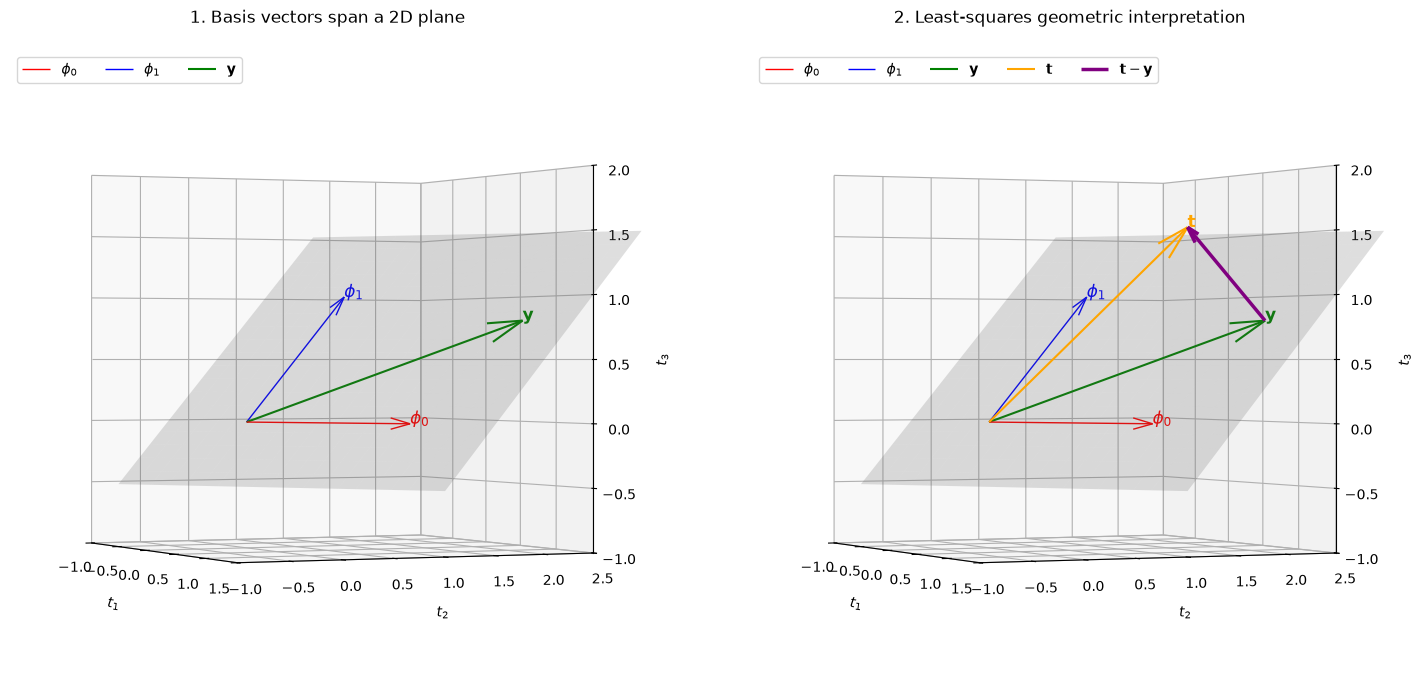

In [79]:
# Plots to visualize geometry of least square for M=2 and N=3
# Read previous section to understand the equations

import matplotlib.pyplot as plt
import numpy as np

axis_max_val = 2.0

# 1. Define basis vectors
phi_0 = np.array([1, 1, 0])  # varphi_0 (3,)
phi_1 = np.array([0, 1, 1])  # varphi_1 (3,)

# Design matrix
Phi = np.column_stack((phi_0, phi_1))  # \Phi 3x2

# Weights
w_0 = 1.2
w_1 = 0.8

w = np.array([w_0, w_1])  # \mathbf{w} (2,)

# Prediction vector
y = Phi @ w  # \mathbf{y} (3,)

# Target vector
t = np.array([1.5, 1.0, 1.5])  # (3,)

# Residual
residual = t - y  # (3,)

# --------------------------------------------------
# 2. Generate plane
# --------------------------------------------------

a = np.linspace(np.min(phi_0) - 0.5, np.max(phi_0) + 0.5, 20)
b = np.linspace(np.min(phi_1) - 0.5, np.max(phi_1) + 0.5, 20)

A, B = np.meshgrid(a, b)

X = A * phi_0[0] + B * phi_1[0]
Y = A * phi_0[1] + B * phi_1[1]
Z = A * phi_0[2] + B * phi_1[2]

# --------------------------------------------------
# 3. Helper function for drawing vectors
# --------------------------------------------------


def draw_vector(ax, vector, color, label, linewidth=1.0):
    ax.quiver(
        0,
        0,
        0,
        *vector,
        color=color,
        arrow_length_ratio=0.12,
        linewidth=linewidth,
        label=label,
    )

    # Write vector name next to its endpoint
    ax.text(
        *vector,
        label,
        color=color,
        fontsize=12,
    )


# --------------------------------------------------
# 4. Create subplots
# --------------------------------------------------

fig = plt.figure(figsize=(15, 7))

ax1 = fig.add_subplot(121, projection="3d")
ax2 = fig.add_subplot(122, projection="3d")

# --------------------------------------------------
# 5. First subplot: Basis vectors and plane
# --------------------------------------------------

ax1.set_title("1. Basis vectors span a 2D plane", pad=20)

ax1.plot_surface(
    X,
    Y,
    Z,
    alpha=0.2,
    color="gray",
    edgecolor="none",
)

draw_vector(ax1, phi_0, "red", r"$\phi_0$")
draw_vector(ax1, phi_1, "blue", r"$\phi_1$")
draw_vector(ax1, y, "green", r"$\mathbf{y}$", linewidth=1.5)

# --------------------------------------------------
# 6. Second subplot: Target and prediction
# --------------------------------------------------

ax2.set_title("2. Least-squares geometric interpretation", pad=20)

ax2.plot_surface(
    X,
    Y,
    Z,
    alpha=0.2,
    color="gray",
    edgecolor="none",
)

draw_vector(ax2, phi_0, "red", r"$\phi_0$")
draw_vector(ax2, phi_1, "blue", r"$\phi_1$")
draw_vector(ax2, y, "green", r"$\mathbf{y}$", linewidth=1.5)
draw_vector(ax2, t, "orange", r"$\mathbf{t}$", linewidth=1.5)

# Residual vector: starts at y and ends at t
ax2.quiver(
    *y,
    *residual,
    color="purple",
    arrow_length_ratio=0.12,
    linewidth=2.5,
    label=r"$\mathbf{t}-\mathbf{y}$",
)

# --------------------------------------------------
# 7. Configure axes
# --------------------------------------------------
for ax in [ax1, ax2]:
    ax.set_xlabel(r"$t_1$", labelpad=10)
    ax.set_ylabel(r"$t_2$", labelpad=10)
    ax.set_zlabel(r"$t_3$", labelpad=10)

    ax.set_xlim(-1.0, 1.5)
    ax.set_ylim(-1.0, 2.5)
    ax.set_zlim(-1.0, 2.0)

    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=0, azim=-25)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(loc="upper left", ncol=len(labels))

plt.tight_layout()
plt.show()